# Scientific Programming (MSB1015) Course Project Data Overview

# Visualization of the Preprocessed and Extracted Data
Visual sanity-checks and exploratory views of the per-session `.npz` files extracted by `Data_Preparation_Selection.ipynb`. Each file holds one session's whole-movie population raster with the following fields:

- `counts`: `int16`, shape `[n_repeats, n_bins, n_units]`; spikes per bin, per movie repeat, per unit (aligned to movie onset)
- `unit_ids` `[n_units]`, `regions` `[n_units]` (visual-area label, aligned to axis 2 of `counts`)
- `bin_starts` `[n_bins]` (bin left-edge, s, relative to movie onset), `bin_size` (s), `onsets` `[n_repeats]`
- `session_id`, `movie`

## Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from paths import EXTRACTED_DIR

## Setup

In [4]:
# Fixed region order + Okabe-Ito colorblind-safe categorical palette (identity encoding)
REGION_ORDER = ["VISp", "VISl", "VISal", "VISrl", "VISam", "VISpm"]
REGION_COLORS = {
    "VISp":  "#0072B2",  # blue
    "VISl":  "#E69F00",  # orange
    "VISal": "#009E73",  # green
    "VISrl": "#D55E00",  # vermillion
    "VISam": "#CC79A7",  # reddish purple
    "VISpm": "#56B4E9",  # sky blue
}

# plotting configurations
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

## Loaders & helpers

In [5]:
def list_sessions(extracted_dir=EXTRACTED_DIR):
    """
    Lists the session files in the extracted directory, sorted by name.
    """
    return sorted(Path(extracted_dir).glob("session_*.npz"))

def load_session(path):
    """
    Loads a session from a .npz file and returns a dict with the relevant data
    """
    data = np.load(path, allow_pickle=True)
    return dict(
        counts     = data["counts"],                                  # [rep, bin, unit] int16
        unit_ids   = np.asarray(data["unit_ids"]),
        regions    = np.asarray(data["regions"]).astype(str),         # bytes/obj -> str
        bin_starts = np.asarray(data["bin_starts"], dtype=float),     # s, rel. to onset
        bin_size   = float(data["bin_size"]),
        onsets     = np.asarray(data["onsets"], dtype=float),
        session_id = int(data["session_id"]),
        movie      = str(data["movie"]),
        path       = str(path),
    )

def rate_from_counts(counts, bin_size):
    """
    Returns the firing rate in Hz derived from the Spike counts (same shape).
    """
    return counts.astype(float) / bin_size

## Dataset overview

In [6]:
sessions = list_sessions() # list extracted sessions
print(f"{len(sessions)} extracted session(s) in {EXTRACTED_DIR}\n") # number of sessions found in the extracted directory

# list metadata for each session, and count units per region
rows, per_region = [], {r: [] for r in REGION_ORDER}
# iterates over all sessions
for session_id in sessions:
    session = load_session(session_id)  #loads session
    n_rep, n_bin, n_unit = session["counts"].shape  # extracts number of repetitions, bins and units
    rows.append(dict(session_id=session["session_id"],
                     n_repeats=n_rep,
                     n_bins=n_bin,
                     n_units=n_unit,
                     dur_s=round(n_bin * session["bin_size"], 1),
                     movie=session["movie"]))
    
    for region in REGION_ORDER:
        per_region[region].append(int((session["regions"] == region).sum()))

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print(f"\ntotal QC-passing units across sessions: {summary.n_units.sum():,}")

32 extracted session(s) in C:\Users\Mariu\Desktop\Scientific_Programming_Project\allen_ecephys\extracted

 session_id  n_repeats  n_bins  n_units  dur_s             movie
  715093703         20    3002      161   30.0 natural_movie_one
  719161530         20    3002      110   30.0 natural_movie_one
  721123822         20    3002      126   30.0 natural_movie_one
  732592105         20    3002      230   30.0 natural_movie_one
  737581020         20    3002       82   30.0 natural_movie_one
  739448407         20    3002      103   30.0 natural_movie_one
  742951821         20    3002      139   30.0 natural_movie_one
  743475441         20    3002      116   30.0 natural_movie_one
  744228101         20    3002       70   30.0 natural_movie_one
  746083955         20    3002      129   30.0 natural_movie_one
  750332458         20    3002      185   30.0 natural_movie_one
  750749662         20    3002      170   30.0 natural_movie_one
  751348571         20    3002      178   30.0 na

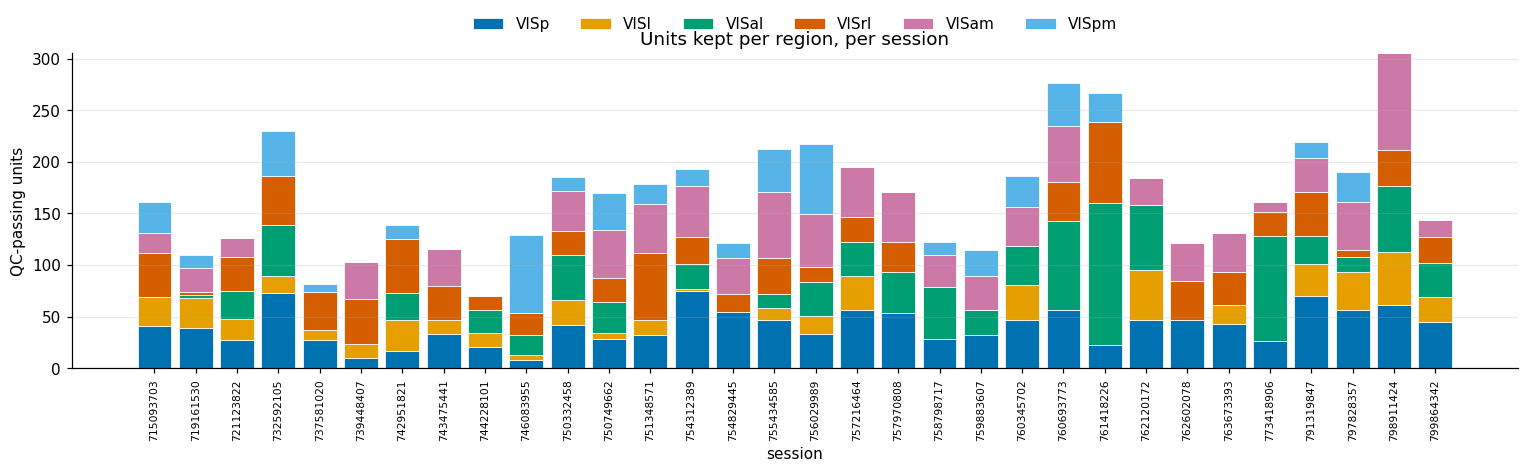

In [7]:
# Units kept per region, per session (stacked)
labels = summary.session_id.astype(str).tolist()
x = np.arange(len(labels))  # one position per session label, for plotting (where to draw each session's bar and tick)
fig, ax = plt.subplots(figsize=(min(14, 2 + 0.4 * len(labels)), 4.5))
bottom = np.zeros(len(labels))

# iterates over regions in REGION_ORDER, retrieves the corresponding values from per_region, and creates a stacked bar plot for each region. The bottom variable keeps track of the cumulative height of the bars to ensure proper stacking.
for r in REGION_ORDER:
    vals = np.array(per_region[r])
    ax.bar(x, vals, bottom=bottom, width=0.82, color=REGION_COLORS[r],
           edgecolor="white", linewidth=0.5, label=r)
    bottom += vals

# plotting
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_xlabel("session"); ax.set_ylabel("QC-passing units")
ax.set_title("Units kept per region, per session")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## Firing-rate distribution by region with all sessions pooled
Same per-unit view as above, but every unit from every session is pooled into one distribution per region (so high-yield sessions contribute more units). `n` per region is shown on the x-axis.

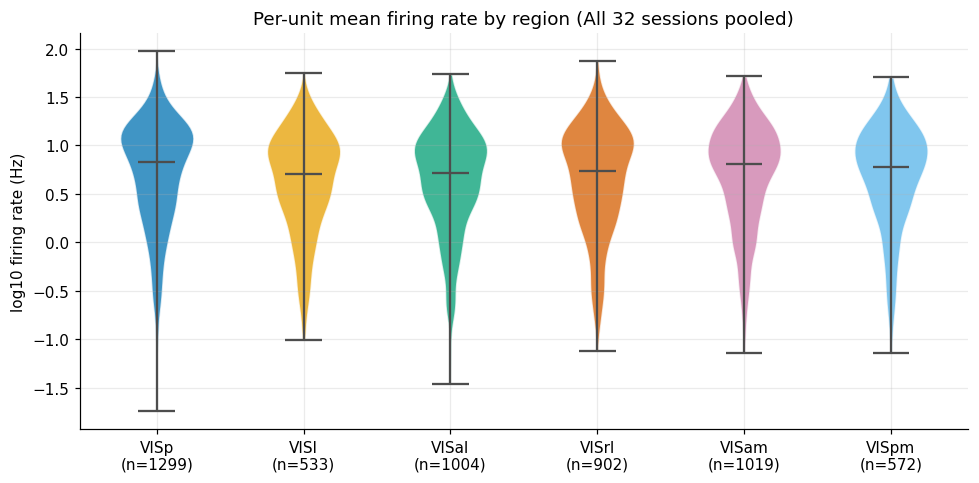

In [8]:
# Per-unit mean firing rate by region, pooled across ALL sessions (every unit, every mouse)
rate_by_region = {r: [] for r in REGION_ORDER}
# iterates over all sessions (file paths)
for _session_path in list_sessions():
    _session_data = load_session(_session_path)
    _ur = rate_from_counts(_session_data["counts"].mean(axis=(0, 1)), _session_data["bin_size"])   # extracts firing rates per unit in Hz
    for region in REGION_ORDER:
        rate_by_region[region].extend(_ur[_session_data["regions"] == region].tolist())  # determines firing rate by region

data, cols, labs, n_units = [], [], [], []
# iterates over the brain regions
for region in REGION_ORDER:
    v = np.asarray(rate_by_region[region])
    v = v[v > 0]     # removes 0 or negative rates (log10 undefined for those)
    if len(v) == 0:  # if no rates remain -> skip to next region
        continue
    data.append(np.log10(v))            # adds log10 rates to data
    cols.append(REGION_COLORS[region])  # adds region's color to cols
    labs.append(region)                 # adds name to labs
    n_units.append(len(v))              # adds unit count to n_units

fig, ax = plt.subplots(figsize=(9, 4.5))
parts = ax.violinplot(data, showmedians=True)

for body, color in zip(parts["bodies"], cols):  # pairs each violin shape with its region's colors
    body.set_facecolor(color)        # sets violin fill color
    body.set_alpha(0.75)         # transparent color
    body.set_edgecolor("white")  # white outline

# styles the violin plot's summary lines and (if present) medians, minima, maxima and center bars
for key in ("cmedians", "cmins", "cmaxes", "cbars"):
    if key in parts:
        parts[key].set_color("0.3")

ax.set_xticks(range(1, len(labs) + 1))
ax.set_xticklabels([f"{l}\n(n={n})" for l, n in zip(labs, n_units)])
ax.set_ylabel("log10 firing rate (Hz)")
ax.set_title(f"Per-unit mean firing rate by region (All {len(list_sessions())} sessions pooled)")

plt.tight_layout()
plt.show()
